# Online Retail II – Sales & Customer Analytics
**YBS405 Big Data Management – Project Notebook**

Dataset: [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii) – all transactions of a UK-based online gift retailer between 01/12/2009 and 09/12/2011 (~1.07M rows).

**Research questions**
1. How does revenue develop over time and is there seasonality?
2. Which products and countries drive revenue?
3. When do customers order (day / hour)?
4. How large is the cancellation problem?
5. Who are the most valuable customers (RFM segmentation) and how well are customers retained (cohort analysis)?

In [1]:
import sys, json
sys.path.insert(0, '../src')
import pandas as pd
from IPython.display import Image, display
import clean, analysis
pd.set_option('display.float_format', '{:,.2f}'.format)

## 1. Data loading & cleaning
The raw Excel file has two sheets (2009-2010 and 2010-2011). `clean.py` merges them and applies the cleaning steps below. Cancellations (invoice numbers starting with **C**) are kept in a separate table so they can be analysed on their own instead of silently reducing revenue.

In [2]:
raw = clean.load_raw()
print(raw.shape)
raw.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
raw.info()
print('\nMissing values per column:')
raw.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 117.3 MB

Missing values per column:


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [4]:
sales, cancels, log = clean.clean(raw)
log

,step,rows
0,Raw data (2 sheets merged),1067371
1,Exact duplicate rows removed,1033036
2,Cancellation invoices separated,1013932
3,Non-positive quantity removed,1010539
4,Non-positive price removed,1007913
5,Non-product stock codes removed,1003417
6,of which with Customer ID (used for customer...,776579


In [5]:
sales.describe()[['Quantity', 'Price', 'Revenue']]

,Quantity,Price,Revenue
count,"1,003,417.00","1,003,417.00","1,003,417.00"
mean,11.15,3.34,19.58
min,1.00,0.03,0.06
25%,1.00,1.25,4.13
50%,4.00,2.10,10.08
75%,12.00,4.13,17.70
max,"80,995.00","1,157.15","168,469.60"
std,128.73,4.76,199.98


## 2. Overview KPIs

In [6]:
sales, cancels = analysis.load()
pd.Series(analysis.overview(sales, cancels))

rows_clean                  1003417
date_min                 2009-12-01
date_max                 2011-12-09
total_revenue         19,645,617.79
n_invoices                    39516
n_customers                    5852
n_products                     4731
n_countries                      43
avg_order_value              497.16
median_order_value           301.23
guest_revenue_share            0.13
dtype: object

## 3. Revenue over time

{'peak_month': '2011-11',
 'peak_month_revenue': 1452115.98,
 'low_month': '2011-02',
 'low_month_revenue': 507866.54,
 'sep_nov_share': 0.36663031105264715}

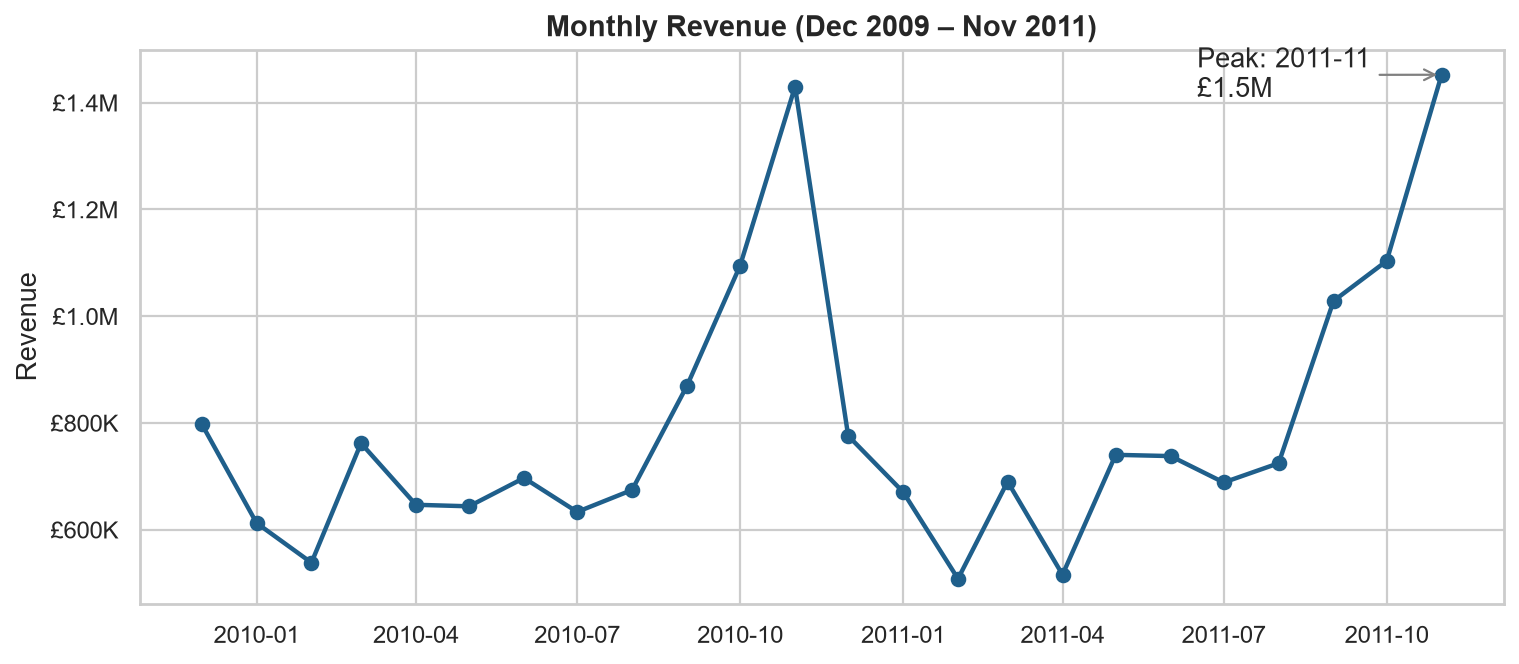

In [7]:
display(analysis.fig_monthly_trend(sales))
Image('../figures/01_monthly_revenue.png')

{'rev_2010_jan_nov': 8599594.13,
 'rev_2011_jan_nov': 8857690.93,
 'yoy_growth': 0.030012672237590632}

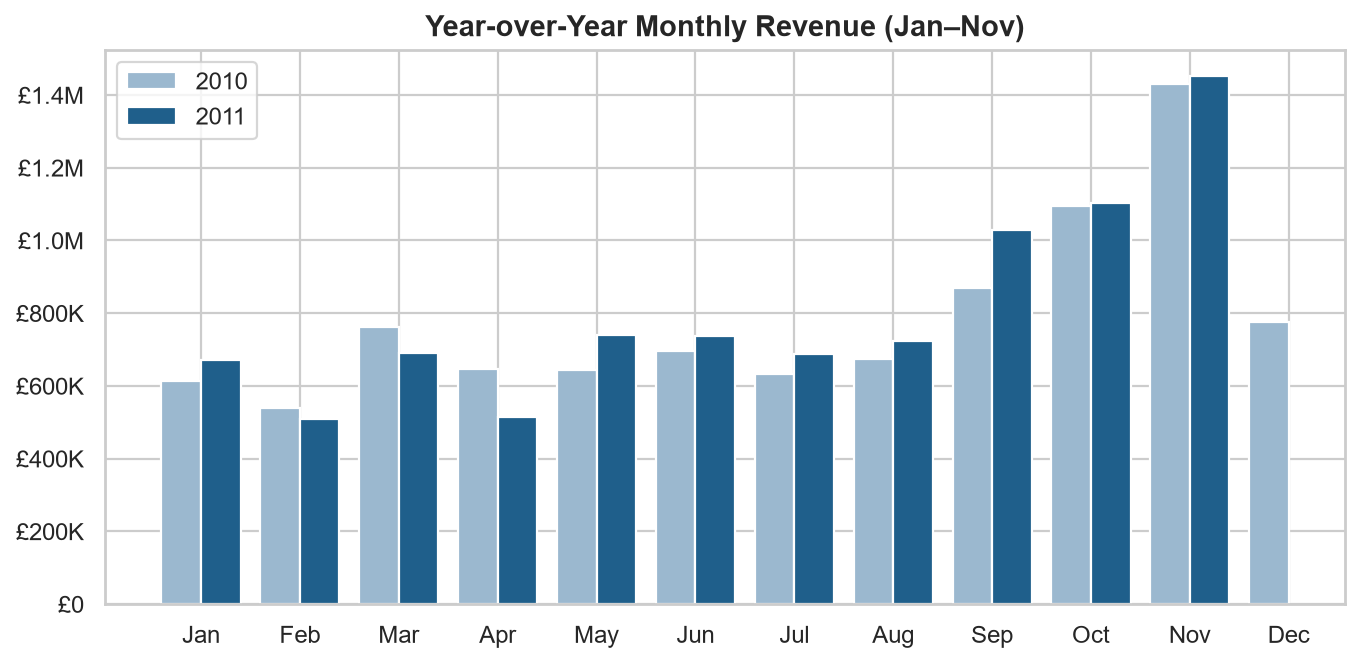

In [8]:
display(analysis.fig_yoy(sales))
Image('../figures/02_yoy_revenue.png')

Revenue is strongly seasonal: it climbs from September and peaks in November, which matches the retailer's wholesale customers stocking up for Christmas.

## 4. Products and countries

{'top_product_revenue_name': 'Regency Cakestand 3 Tier',
 'top_product_revenue': 330590.32,
 'top_product_qty_name': 'World War 2 Gliders Asstd Designs',
 'top100_products_revenue_share': 0.2945481929789697,
 'n_products': 4731}

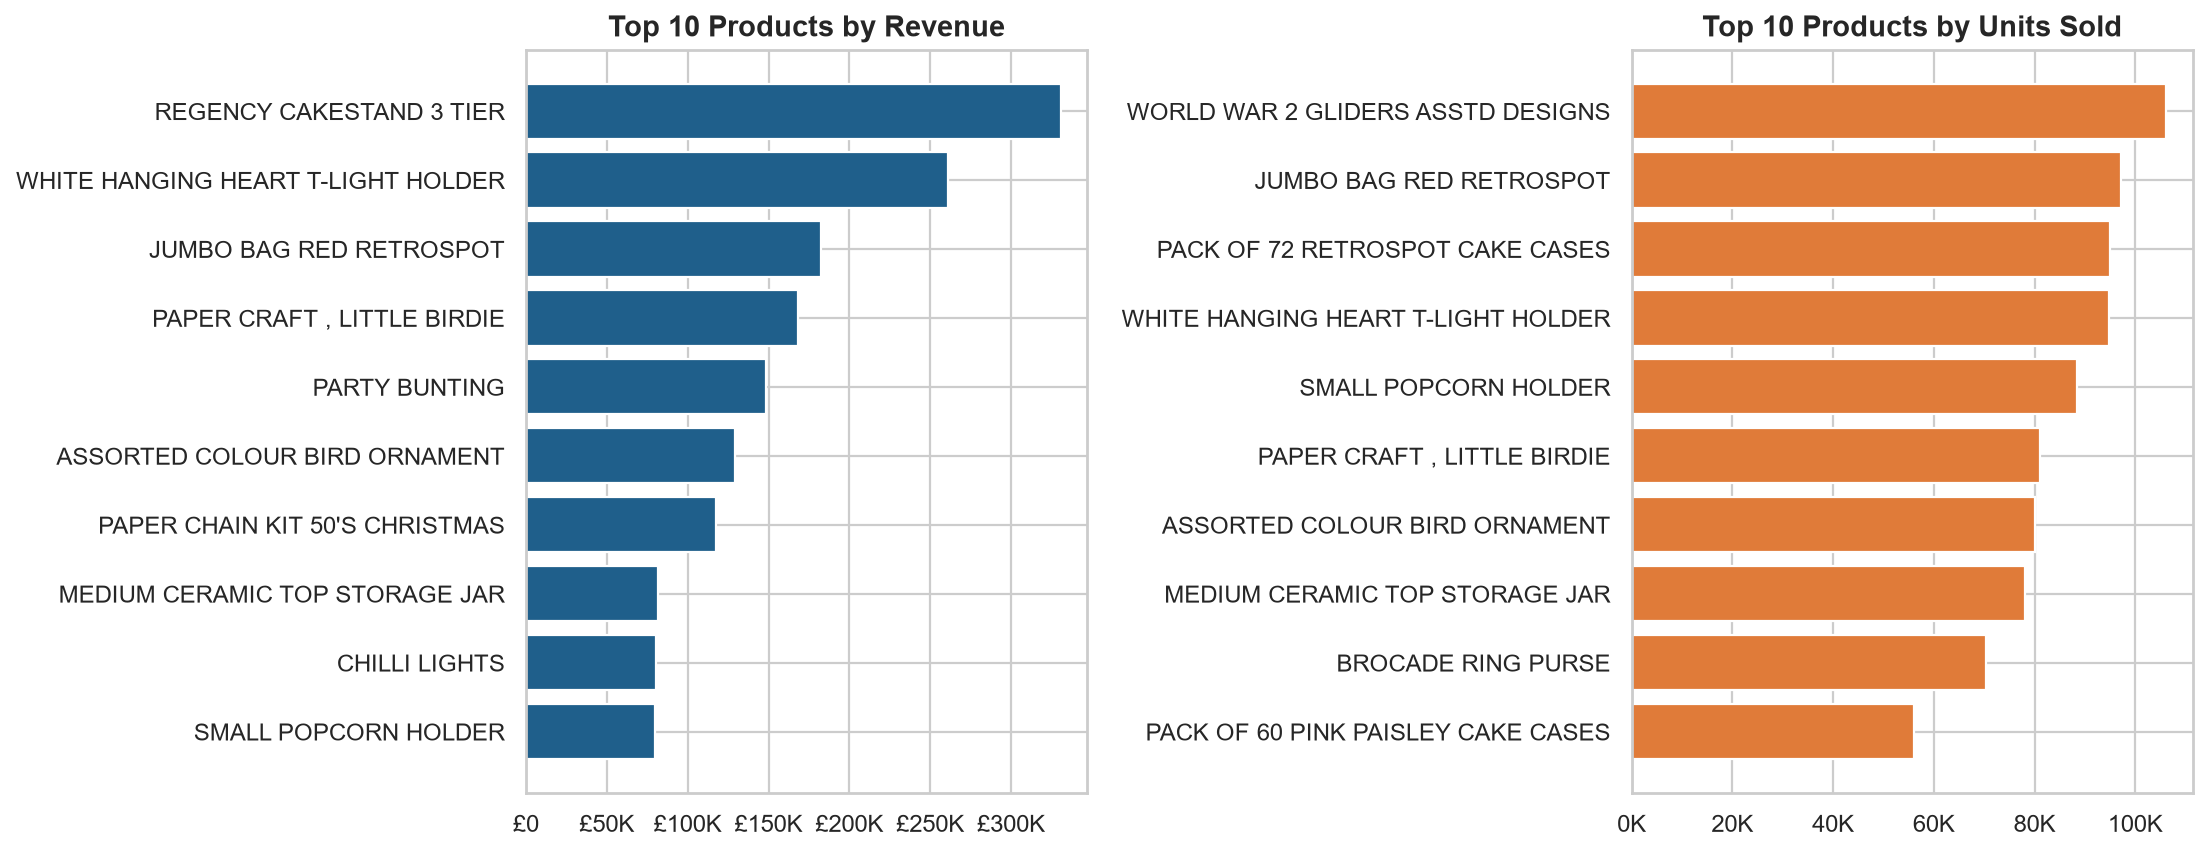

In [9]:
display(analysis.fig_top_products(sales))
Image('../figures/03_top_products.png')

{'uk_revenue_share': 0.8552938227553697,
 'top_intl_countries': ['EIRE', 'Netherlands', 'Germany']}

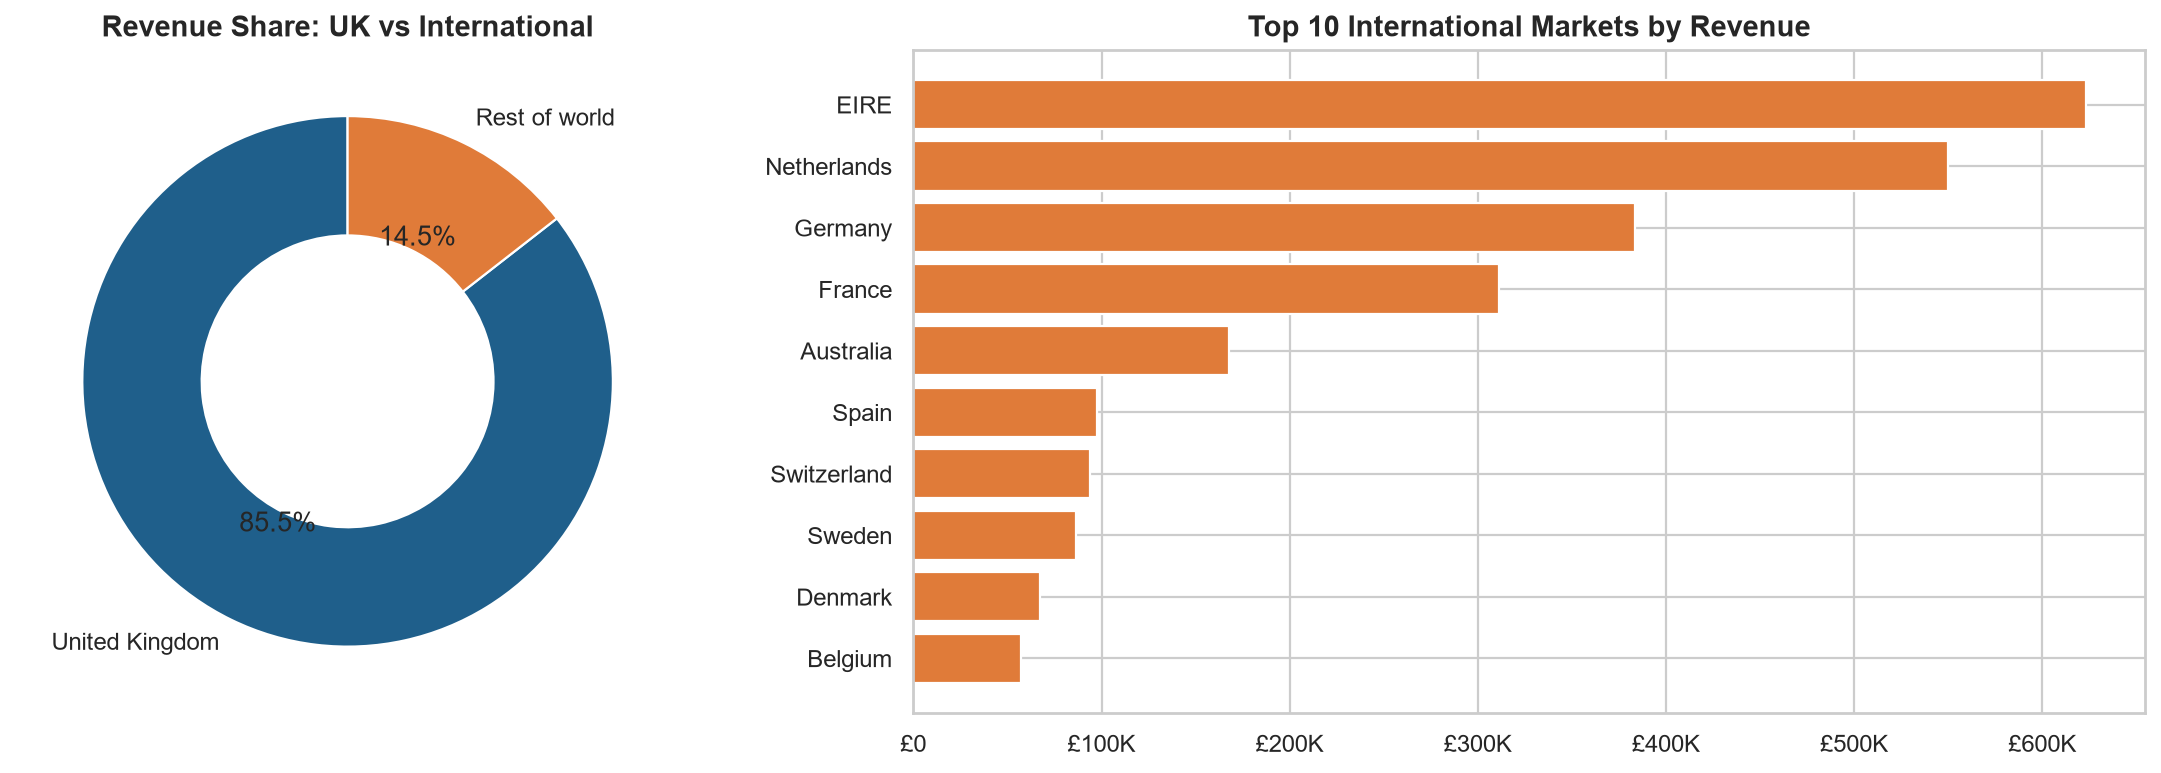

In [10]:
display(analysis.fig_countries(sales))
Image('../figures/04_countries.png')

## 5. When do customers order?

{'busiest_day': 'Thursday', 'busiest_hour': 12, 'saturday_orders': 30}

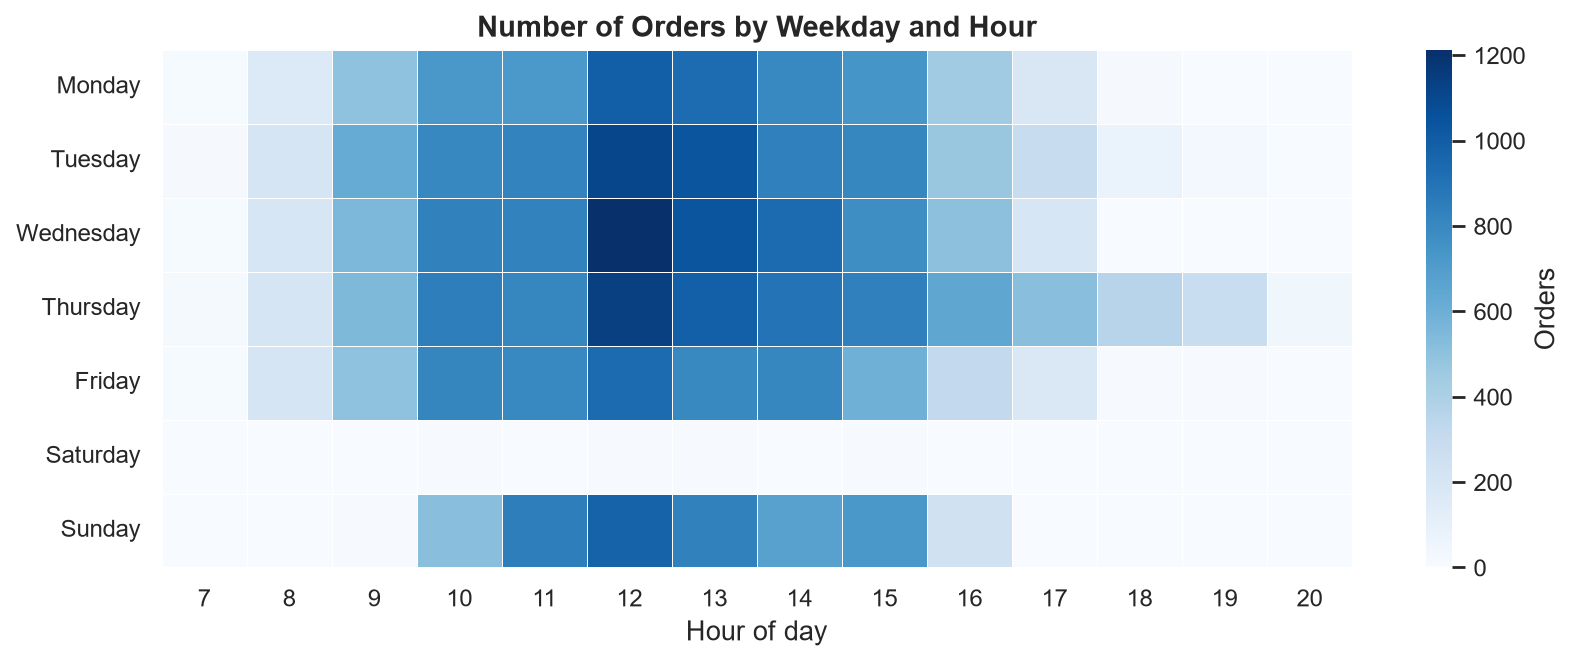

In [11]:
display(analysis.fig_heatmap(sales))
Image('../figures/05_weekday_hour_heatmap.png')

## 6. Cancellations

{'cancel_invoices': 8292,
 'cancel_rate': 0.1734437751004016,
 'cancel_value': 1462050.61}

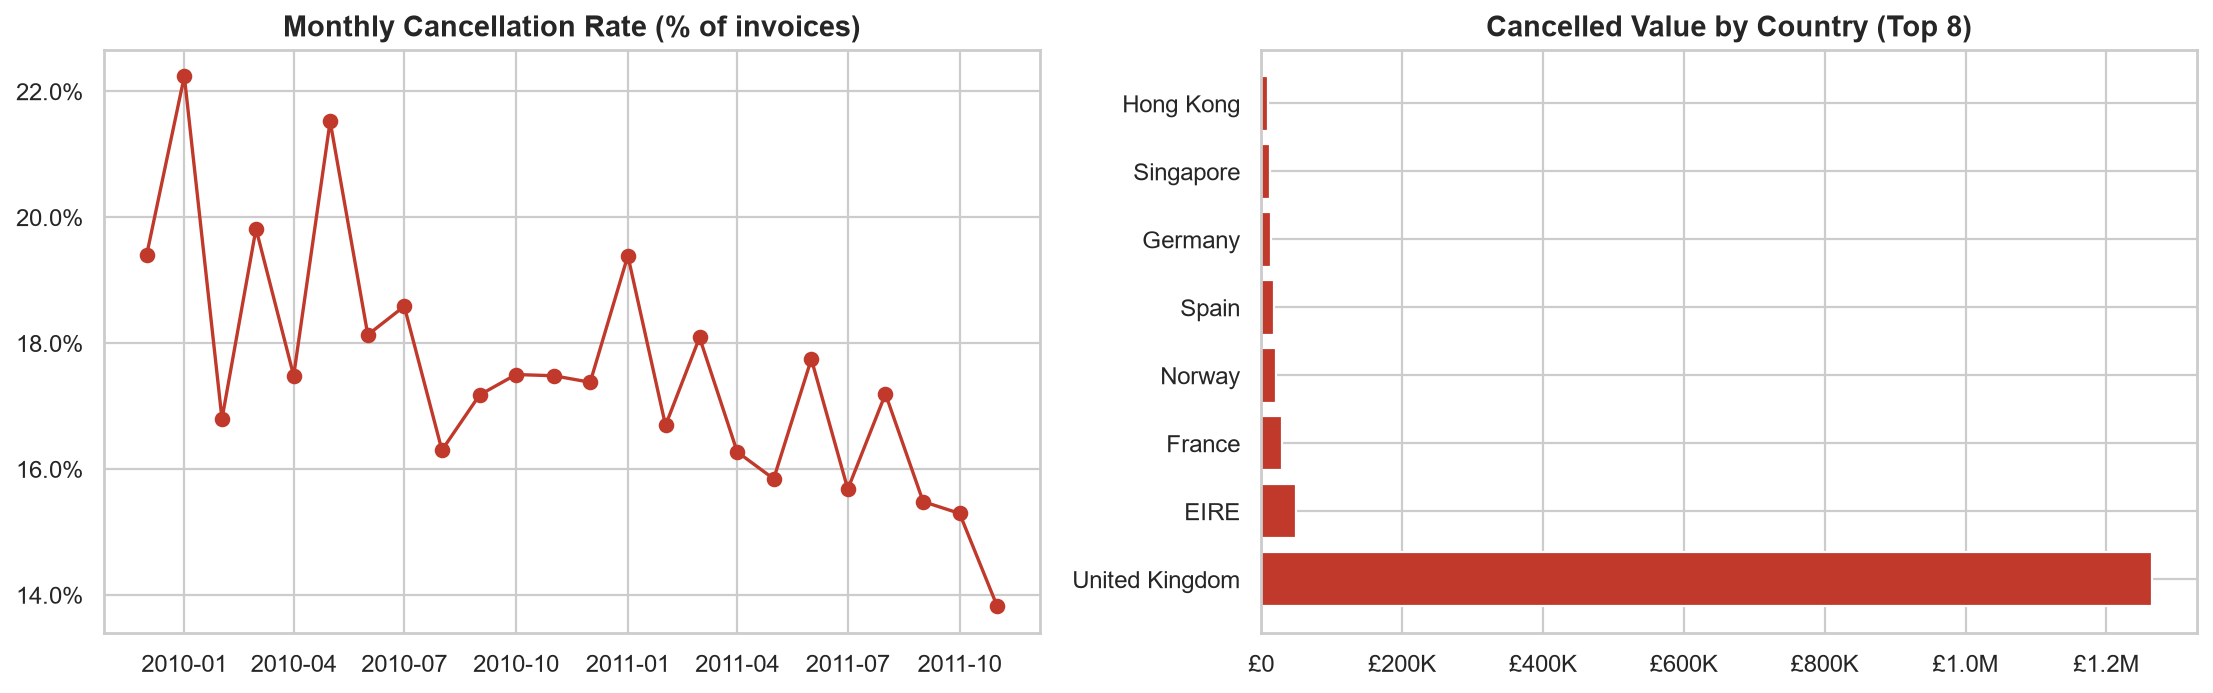

In [12]:
display(analysis.fig_cancellations(sales, cancels))
Image('../figures/06_cancellations.png')

## 7. RFM customer segmentation
Each customer gets a 1–5 score for **Recency** (days since last order), **Frequency** (number of orders) and **Monetary** value (total spend), using quintiles. Segments are defined from R and the average of F and M.

In [13]:
rfm = analysis.rfm_table(sales)
rfm.head()

,Recency,Frequency,Monetary,R,F,M,Segment
Customer ID,,,,,,,
12346,326,3,"77,352.96",2,3,5,At Risk
12347,2,8,"4,921.53",5,4,5,Champions
12348,75,5,"1,658.40",3,4,4,Loyal Customers
12349,19,3,"3,678.69",5,3,5,Champions
12350,310,1,294.40,2,1,2,Hibernating / Lost


,customers,cust_share,rev_share
Champions,"1,316.00",0.22,0.69
Loyal Customers,"1,198.00",0.20,0.16
New / Promising,562.00,0.10,0.01
At Risk,682.00,0.12,0.10
Need Attention,440.00,0.08,0.01
Hibernating / Lost,"1,654.00",0.28,0.03


{'top20_customer_revenue_share': 0.7715083434882869,
 'median_recency_days': 95.0,
 'one_time_buyer_share': 0.27648667122351334}

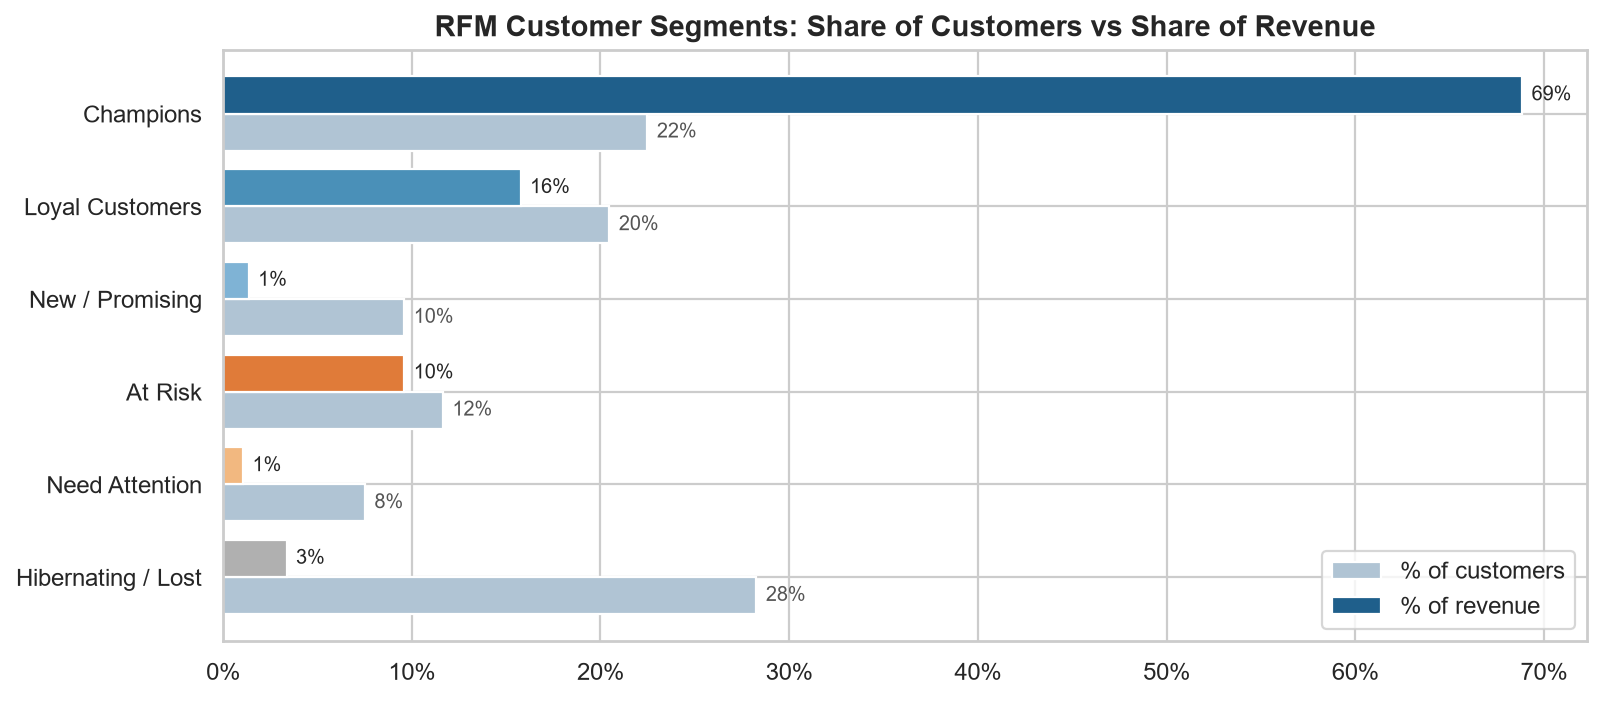

In [14]:
res = analysis.fig_rfm(sales)
display(pd.DataFrame(res.pop('rfm_segments')).T, res)
Image('../figures/07_rfm_segments.png')

## 8. Cohort retention

{'first_cohort_m1_retention': 0.3501577287066246,
 'first_cohort_m12_retention': 0.3764458464773922,
 'avg_m1_retention_other_cohorts': 0.18933379350608595}

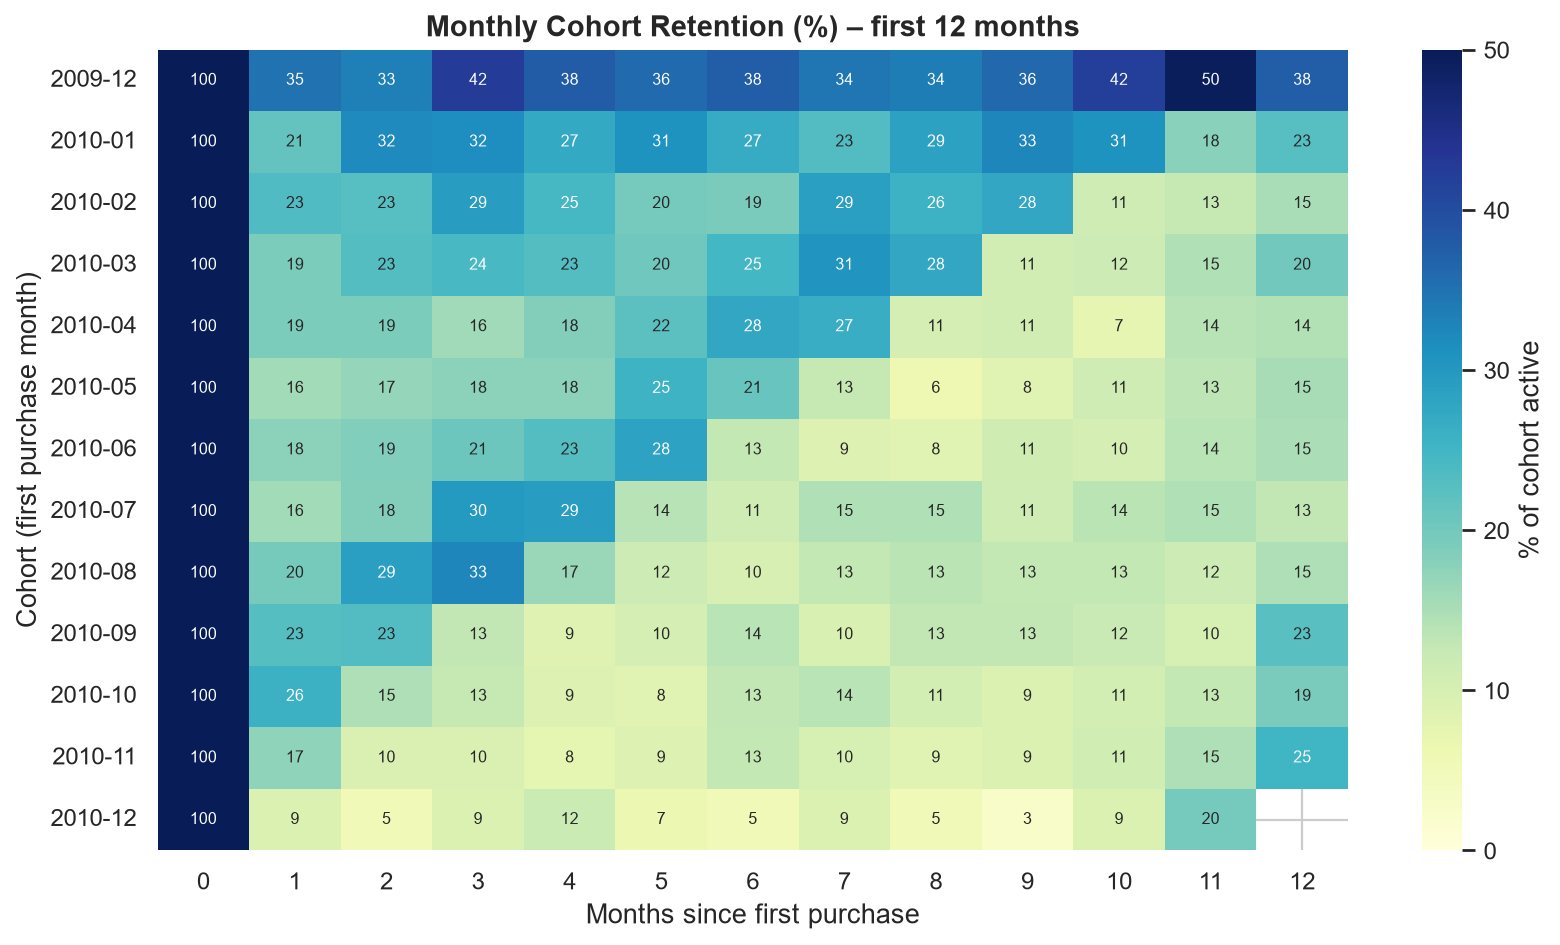

In [15]:
display(analysis.fig_cohort(sales))
Image('../figures/08_cohort_retention.png')

The December 2009 cohort looks unusually loyal because it also contains customers who were already buying before the dataset starts (left-censoring), so later cohorts give a more realistic retention picture.

## 9. Orders, baskets and price

{'median_items_per_order': 15.0, 'orders_over_1000_share': 0.08637007794311165}

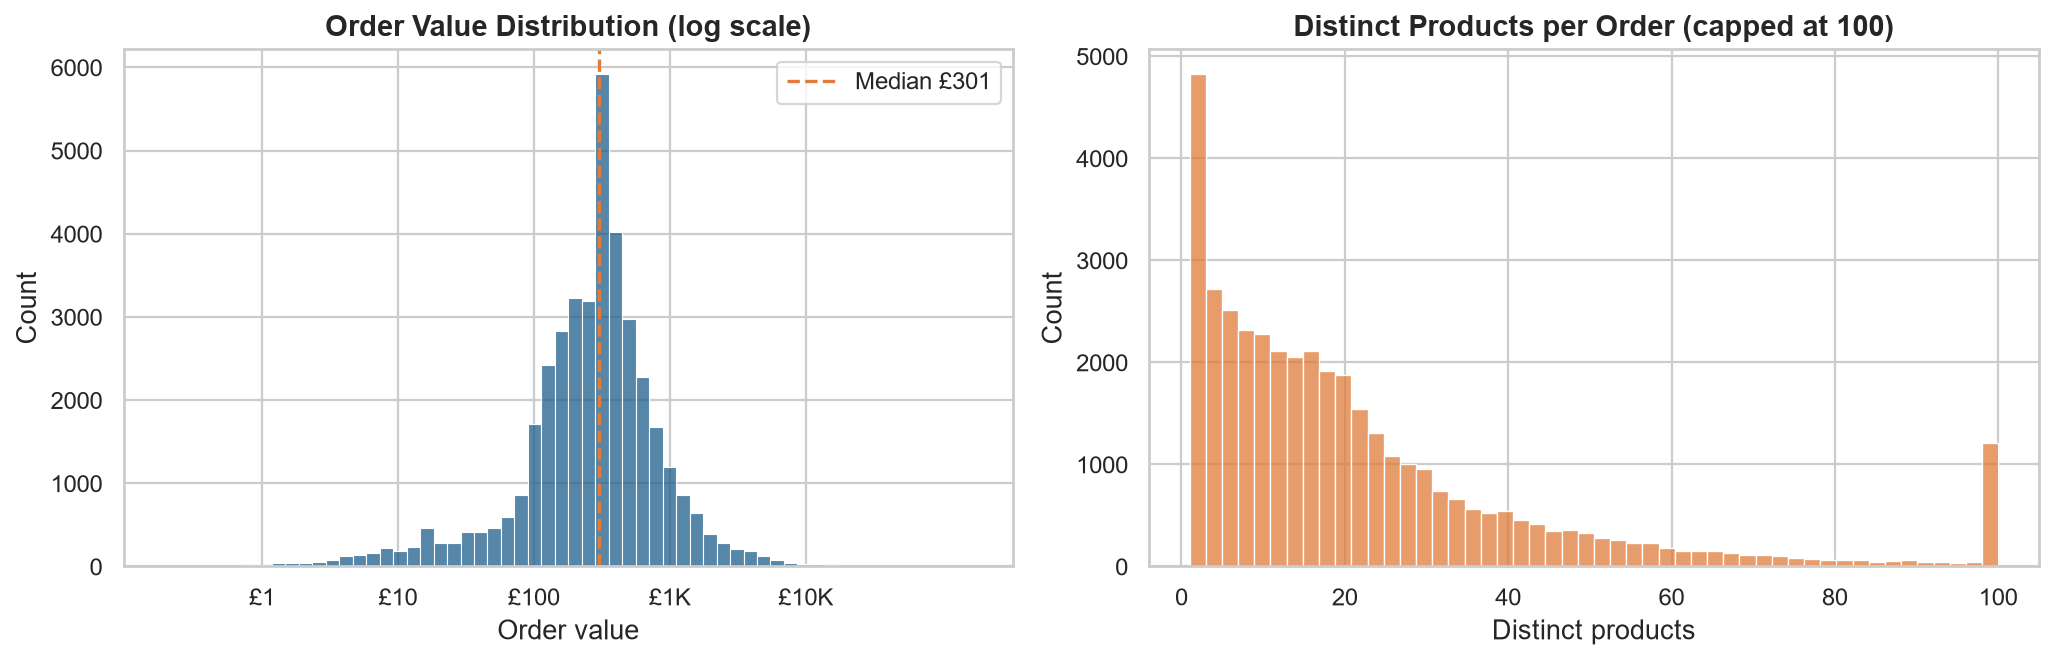

In [16]:
display(analysis.fig_order_value(sales))
Image('../figures/09_order_value.png')

{'price_qty_log_corr': -0.36327644560366057,
 'price_elasticity_slope': -0.7759544077215355}

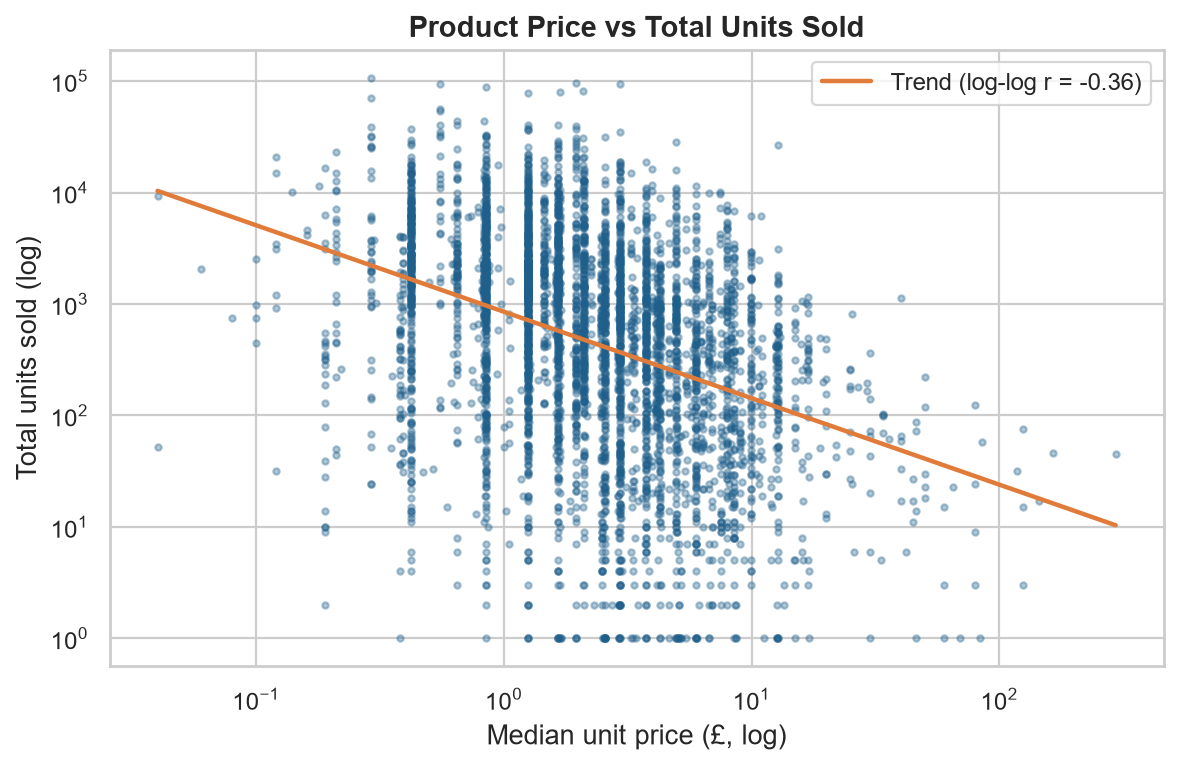

In [17]:
display(analysis.fig_price_quantity(sales))
Image('../figures/10_price_vs_quantity.png')

## 10. Save all metrics
All numbers used in the report and presentation are written to `data/processed/metrics.json`.

In [18]:
metrics = analysis.run_all()
print('saved', len(metrics), 'metric groups')

saved 12 metric groups
